# Clustering Digits

In [1]:
import torch
from torchvision import datasets, transforms, utils
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

In [2]:
from torch.utils.data import DataLoader
from torch.optim import Adam

In [3]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
from tqdm import tqdm
from sklearn.cluster import KMeans
import pickle

In [4]:
from dataUtils import ClusteredEMNIST

In [5]:
from os.path import exists, join as path_join
from os import makedirs

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:
device

device(type='cuda')

In [8]:
emnist_root = 'datasets/emnist'

In [9]:
# Define transformations
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),  # ResNet expects 3 channels
    transforms.Resize((32, 32)),  # Resize to 32x32 as ResNet typically expects this size
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [10]:
datasets.EMNIST.url ="https://biometrics.nist.gov/cs_links/EMNIST/gzip.zip"

In [11]:
print(f"EMNIST splits: {datasets.EMNIST.splits}")

EMNIST splits: ('byclass', 'bymerge', 'balanced', 'letters', 'digits', 'mnist')


## Clustering MNIST

In [12]:
emnist_split = 'mnist'

In [13]:
exps_root = f"clustering_{emnist_split}"
makedirs(exps_root, exist_ok=True)

In [14]:
num_unique_labels = 10

In [15]:
# Load the EMNIST dataset
train_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,
    train=True,
    transform=transform,
    download=True
)

In [16]:
test_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,  # Use the same split as for the train dataset
    train=False,
    transform=transform,
)

In [17]:
len(test_dataset)

10000

In [18]:
def imshow(img, title):
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (2, 1, 0)), cmap='gray')
    plt.title(title)
    plt.show()

### Model definition

In [19]:
# Load a pre-trained ResNet model
class ResNetForMNIST(nn.Module):
    def __init__(self, num_classes=num_unique_labels):
        super(ResNetForMNIST, self).__init__()
        self.resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.resnet.fc = nn.Identity()  # Remove the final fully connected layer

    def forward(self, x):
        return self.resnet(x)

In [20]:
def eval_model(model, data_loader):
    model.eval()
    with torch.no_grad():  # Disable gradient computation for evaluation
        mean_valid_loss = 0
        total = 0
        correct = 0
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)  # Move data to GPU
            features = model(images)
            mean_valid_loss += criterion(classification_layer(features), labels)
            outputs = classification_layer(features)
            _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        mean_valid_loss /= total
        acc = correct/total
        
    return acc, mean_valid_loss

In [21]:
# Initialize the model
model = ResNetForMNIST().to(device)

# Define the final classification layer (for training purposes)
classification_layer = nn.Linear(512, num_unique_labels).to(device)  # 512 is the output size of resnet18's penultimate layer

In [22]:
# Prepare DataLoader with the transformation applied
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Prepare DataLoader for evaluation training acc and loss
valid_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = Adam(list(model.parameters()) + list(classification_layer.parameters()), lr=0.001)


### Training 
If there are pre-computed weights, use them. Otherwise, train

In [23]:
if not exists(path_join(exps_root, f'resnet_{emnist_split}.pth')):
    # Training loop
    eval_step= 6000
    num_epochs = 10
    for epoch in tqdm(range(num_epochs)):
        for i, (images, labels) in enumerate(train_loader):
            model.train()
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            features = model(images)
            outputs = classification_layer(features)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            if i % eval_step == 0:
                eval_acc, eval_loss = eval_model(model, valid_loader)
                test_acc, test_loss = eval_model(model, test_loader)
                print(f"[Train | Test] acc: {eval_acc * 100:.2f} | {test_acc * 100:.2f}, loss {eval_loss:.6f} | {test_loss:.6f}")
        print(f"Epoch {epoch+1}, Loss: {loss.item()}")


  0%|          | 0/10 [00:00<?, ?it/s]

[Train | Test] acc: 10.09 | 10.08, loss 0.037591 | 0.037788


 10%|█         | 1/10 [00:54<08:14, 54.99s/it]

Epoch 1, Loss: 0.023351116105914116
[Train | Test] acc: 98.71 | 98.52, loss 0.000806 | 0.000840


 20%|██        | 2/10 [01:40<06:33, 49.13s/it]

Epoch 2, Loss: 0.035567548125982285
[Train | Test] acc: 99.26 | 99.06, loss 0.000433 | 0.000529


... (12 outputs left out)

 90%|█████████ | 9/10 [07:11<00:47, 47.50s/it]

Epoch 9, Loss: 0.0006513326661661267
[Train | Test] acc: 99.55 | 99.36, loss 0.000269 | 0.000415


100%|██████████| 10/10 [07:58<00:00, 47.88s/it]

Epoch 10, Loss: 0.001586508471518755


In [24]:
# Save the model's state dictionary
if (not exists(path_join(exps_root, f'resnet_{emnist_split}.pth'))) or (not exists(path_join(exps_root, f'resnet_{emnist_split}.pth'))):
    torch.save(model.state_dict(), path_join(exps_root, f'resnet_{emnist_split}.pth'))
    torch.save(classification_layer.state_dict(), path_join(exps_root, f'resnet_class_layer_{emnist_split}.pth'))

In [25]:
# Load the saved state dictionary
if exists(path_join(exps_root, f'resnet_{emnist_split}.pth')):
    model.load_state_dict(torch.load(path_join(exps_root, f'resnet_{emnist_split}.pth')))
    classification_layer.load_state_dict(torch.load(path_join(exps_root, f'resnet_class_layer_{emnist_split}.pth')))

In [26]:
model.eval()  # Set the model to evaluation mode

correct = 0
total = 0

model.eval()
with torch.no_grad():  # Disable gradient computation for evaluation
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)  # Move data to GPU
        features = model(images)
        outputs = classification_layer(features)
        _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate accuracy
accuracy = correct / total
print(f'Accuracy of the model on the test set: {accuracy * 100:.2f}%')

Accuracy of the model on the test set: 99.36%


In [27]:
# Extract latent space for clustering
def get_latent_space(model, dataloader):
    model.eval()
    latents = []
    labels = []
    with torch.no_grad():
        for images, _labels in dataloader:
            images = images.to(device)
            features = model(images)
            latents.append(features.cpu())  # Move to CPU for clustering
            labels.append(_labels)
    return torch.cat(latents), torch.cat(labels)


In [28]:
# Function to extract latent features, grouped by digit class
def get_latent_space_by_class(model, dataloader):
    model.eval()
    latent_dict = {i: [] for i in range(num_unique_labels)}  # Dictionary to store latents for each digit
    label_dict = {i: [] for i in range(num_unique_labels)}   # Dictionary to store corresponding labels

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            features = model(images)
            features = features.cpu()

            for i in range(num_unique_labels):
                mask = (labels == i)
                latent_dict[i].append(features[mask])
                label_dict[i].append(labels[mask])

    # Concatenate all the latent features and labels for each digit
    for i in range(10):
        if latent_dict[i]:
            latent_dict[i] = torch.cat(latent_dict[i])
            label_dict[i] = torch.cat(label_dict[i])
    
    return latent_dict, label_dict

# Extract latent space representations grouped by digit class
latent_dict, label_dict = get_latent_space_by_class(model, train_loader)

In [29]:
# Perform clustering for each digit class
cluster_assignments = {}
clustering = {}
for i in range(num_unique_labels):
    if latent_dict[i].size(0) > 0:
        clustering[i] = KMeans(n_clusters=2, random_state=0, n_init='auto')
        cluster_assignments[i] = clustering[i].fit_predict(latent_dict[i])

In [30]:
# Example of how to use the cluster assignments
for i in range(num_unique_labels):
    clusters = cluster_assignments[i]
    labels = label_dict[i]
    count_0 = (clusters == 0).sum()
    count_1 = (clusters == 1).sum()
    print(f"Digit {i}: Cluster 0 count = {count_0}, Cluster 1 count = {count_1} [{100*count_0/(count_0+count_1):.2f}%]")

Digit 0: Cluster 0 count = 1982, Cluster 1 count = 4018 [33.03%]
Digit 1: Cluster 0 count = 3986, Cluster 1 count = 2014 [66.43%]
Digit 2: Cluster 0 count = 2625, Cluster 1 count = 3375 [43.75%]
Digit 3: Cluster 0 count = 3841, Cluster 1 count = 2159 [64.02%]
Digit 4: Cluster 0 count = 3897, Cluster 1 count = 2103 [64.95%]
Digit 5: Cluster 0 count = 3821, Cluster 1 count = 2179 [63.68%]
Digit 6: Cluster 0 count = 1856, Cluster 1 count = 4144 [30.93%]
Digit 7: Cluster 0 count = 1956, Cluster 1 count = 4044 [32.60%]
Digit 8: Cluster 0 count = 4091, Cluster 1 count = 1909 [68.18%]
Digit 9: Cluster 0 count = 3682, Cluster 1 count = 2318 [61.37%]


In [31]:
test_latent_dict, test_label_dict = get_latent_space_by_class(model, test_loader)

test_cluster_assignments = {}
for i in range(num_unique_labels):
    if latent_dict[i].size(0) > 0:
        test_cluster_assignments[i] = clustering[i].predict(test_latent_dict[i])

In [32]:
if exists(path_join(exps_root, f'kmeans_{emnist_split}_clusterings.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_clusterings.pkl'), 'rb') as f:
        clustering = pickle.load(f)

if exists(path_join(exps_root, f'kmeans_{emnist_split}_train_clusters.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_train_clusters.pkl'), 'rb') as f:
        cluster_assignments = pickle.load(f)

if exists(path_join(exps_root, f'kmeans_{emnist_split}_test_clusters.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_test_clusters.pkl'), 'rb') as f:
        test_cluster_assignments = pickle.load(f)

In [33]:
# Example of how to use the cluster assignments
for i in range(num_unique_labels):
    test_clusters = test_cluster_assignments[i]
    test_labels = test_label_dict[i]
    count_0 = (test_clusters == 0).sum()
    count_1 = (test_clusters == 1).sum()
    print(f"Digit {i}: Cluster 0 count = {count_0}, Cluster 1 count = {count_1} [{100*count_0/(count_0+count_1):.2f}%]")

Digit 0: Cluster 0 count = 651, Cluster 1 count = 349 [65.10%]
Digit 1: Cluster 0 count = 650, Cluster 1 count = 350 [65.00%]
Digit 2: Cluster 0 count = 420, Cluster 1 count = 580 [42.00%]
Digit 3: Cluster 0 count = 387, Cluster 1 count = 613 [38.70%]
Digit 4: Cluster 0 count = 649, Cluster 1 count = 351 [64.90%]
Digit 5: Cluster 0 count = 358, Cluster 1 count = 642 [35.80%]
Digit 6: Cluster 0 count = 669, Cluster 1 count = 331 [66.90%]
Digit 7: Cluster 0 count = 301, Cluster 1 count = 699 [30.10%]
Digit 8: Cluster 0 count = 690, Cluster 1 count = 310 [69.00%]
Digit 9: Cluster 0 count = 392, Cluster 1 count = 608 [39.20%]


In [34]:
# Save the KMeans models
if not exists(path_join(exps_root, f'kmeans_{emnist_split}_clusterings.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_clusterings.pkl'), 'wb') as f:
        pickle.dump(clustering, f)
if not exists(path_join(exps_root, f'kmeans_{emnist_split}_train_clusters.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_train_clusters.pkl'), 'wb') as f:
        pickle.dump(cluster_assignments, f)
if not exists(path_join(exps_root, f'kmeans_{emnist_split}_test_clusters.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_test_clusters.pkl'), 'wb') as f:
        pickle.dump(test_cluster_assignments, f)


In [35]:
from sklearn.manifold import TSNE

In [36]:
if not exists(path_join(exps_root, f'tsne_{emnist_split}_train_model.pkl')):
    tsne_dict = {}
    tsne_coords_dict = {}
    for i in tqdm(range(num_unique_labels)):
        tsne_dict[i] = TSNE(n_components=2, random_state=0)
        tsne_coords_dict[i] = tsne_dict[i].fit_transform(latent_dict[i])
        
    with open(path_join(exps_root, f'tsne_{emnist_split}_train_model.pkl'), 'wb') as f:
        pickle.dump(tsne_dict, f)
    with open(path_join(exps_root, f'tsne_{emnist_split}_train_coords.pkl'), 'wb') as f:
        pickle.dump(tsne_coords_dict, f)
else:
    with open(path_join(exps_root, f'tsne_{emnist_split}_train_model.pkl'), 'rb') as f:
        tsne_dict = pickle.load(f)
    with open(path_join(exps_root, f'tsne_{emnist_split}_train_coords.pkl'), 'rb') as f:
        tsne_coords_dict = pickle.load(f)

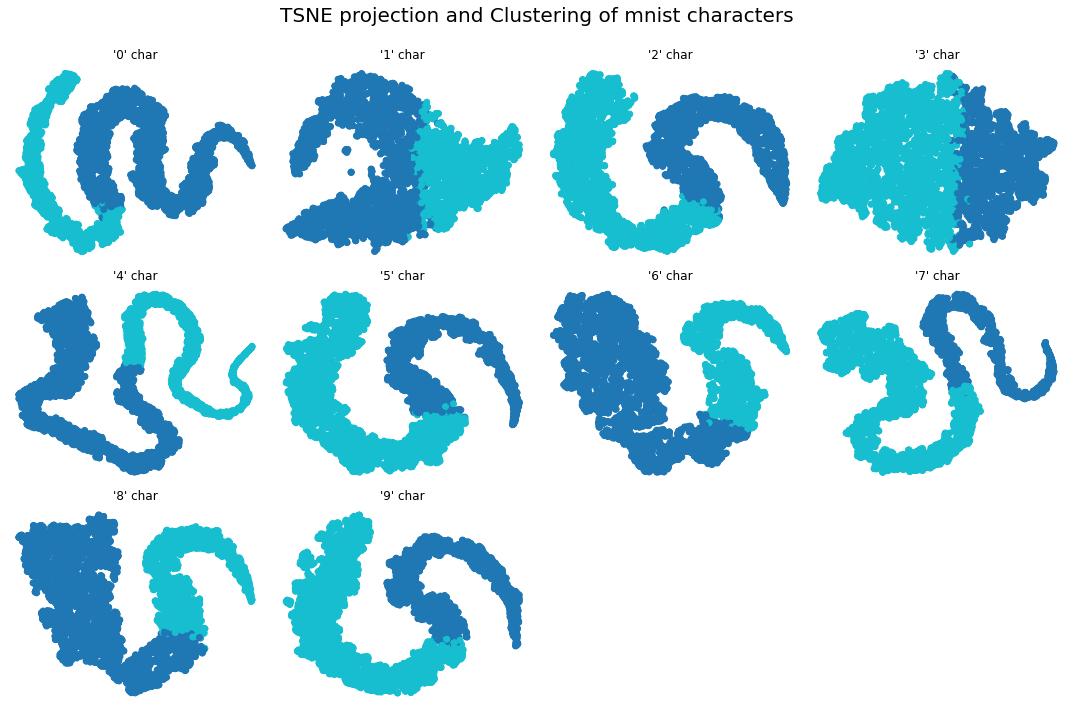

In [37]:
fig = plt.figure()

fig.set_figheight(10)
fig.set_figwidth(15)
cols = 3
rows = num_unique_labels//cols + (num_unique_labels/cols > 0)

for i in range(num_unique_labels):
    ax = fig.add_subplot(cols,rows,i+1)
    ax.axis('off')
    ax.set_title(f"'{train_dataset.classes[i]}' char")
    plt.scatter(tsne_coords_dict[i][:,0], tsne_coords_dict[i][:,1], c=cluster_assignments[i], cmap='tab10')

# plt.subplots_adjust(wspace=0.4, hspace=0.4)
plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.suptitle(f"TSNE projection and Clustering of {emnist_split} characters", fontsize=20)
plt.show()

In [38]:
tsne_coords_dict[0].shape

(6000, 2)

In [39]:
from itertools import chain

In [40]:
latent_dict_all = np.vstack(list(chain([latent_dict[i] for i in range(num_unique_labels)])))
cluster_assignments_all_ = np.hstack(list(chain([cluster_assignments[i] for i in range(num_unique_labels)])))
_tmp_class_assignments_all = np.hstack(list(chain([[i]*len(cluster_assignments[i]) for i in range(num_unique_labels)])))

class_assignments_all = np.vstack([_tmp_class_assignments_all, cluster_assignments_all_]).T

In [41]:
latent_dict_all.shape, cluster_assignments_all_.shape, _tmp_class_assignments_all.shape, class_assignments_all.shape

((60000, 512), (60000,), (60000,), (60000, 2))

In [42]:
class_assignments_all[:, 0:6]

class_assignments_all_str = np.core.defchararray.add(class_assignments_all.astype(str)[:, 0], ' ')
class_assignments_all_str = np.core.defchararray.add(class_assignments_all_str, class_assignments_all.astype(str)[:, 1])

unique_class_assignments_all_str = np.unique(class_assignments_all_str)
color_map = {string: color for string, color in zip(unique_class_assignments_all_str, matplotlib.colormaps.get_cmap('tab20')(range(len(unique_class_assignments_all_str))))}

# Map each entry in merged_array to a color
colors = np.array([color_map[string] for string in class_assignments_all_str])


In [ ]:
tsne_all = TSNE(n_components=2, random_state=0)
tsne_coords_all = tsne_all.fit_transform(latent_dict_all)

In [ ]:
with open(path_join(exps_root, f'tsne_{emnist_split}_all_train_model.pkl'), 'wb') as f:
    pickle.dump(tsne_all, f)
with open(path_join(exps_root, f'tsne_{emnist_split}_all_train_coords.pkl'), 'wb') as f:
    pickle.dump(tsne_coords_all, f)
with open(path_join(exps_root, f'kmeans_{emnist_split}_all_train_clusters.pkl)', 'wb') as f:
    pickle.dump(class_assignments_all, f)

In [ ]:
if exists(path_join(exps_root, f'tsne_{emnist_split}_all_train_model.pkl')):
    with open(path_join(exps_root, f'tsne_{emnist_split}_all_train_model.pkl'), 'rb') as f:
        tsne_all = pickle.load(f)
if exists(path_join(exps_root, f'tsne_{emnist_split}_all_train_coords.pkl'),):
    with open(path_join(exps_root, f'tsne_{emnist_split}_all_train_coords.pkl'), 'rb') as f:
        tsne_coords_all = pickle.load(f)
if exists(path_join(exps_root, f'kmeans_{emnist_split}_all_train_clusters.pkl')):
    with open(path_join(exps_root, f'kmeans_{emnist_split}_all_train_clusters.pkl'), 'rb') as f:
        class_assignments_all = pickle.load(f)

In [ ]:
fig = plt.figure()

fig.set_figheight(10)
fig.set_figwidth(15)

plt.scatter(tsne_coords_all[:,0], tsne_coords_all[:,1], c=colors, cmap='tab10')
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[string], markersize=8, label=string) for string in unique_class_assignments_all_str]
plt.legend(handles=handles, title="Clusters")
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
train_dataset

In [ ]:
# Step 6: Instantiate the custom dataset
clustered_train_dataset = ClusteredEMNIST(train_dataset,
                                          model, clustering, num_unique_labels, batch_size=64)
clustered_test_dataset = ClusteredEMNIST(test_dataset,
                                          model, clustering, num_unique_labels, batch_size=64)

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
    ])

# Load the EMNIST dataset
train_simple_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,
    train=True,
    transform=transform,
    download=True
)

test_simple_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,  # Use the same split as for the train dataset
    train=False,
    transform=transform,
    download=True
)

clustered_train_dataset.original_dataset = train_simple_dataset
clustered_test_dataset.original_dataset = test_simple_dataset

In [ ]:
# Step 7: Access the data
img, target, sub_class = clustered_train_dataset[0]
print(f"Image shape: {img.shape}, Target: {target}, Sub-class: {sub_class}")

In [ ]:
count = {}
for img, target, sub_class in clustered_train_dataset:
    count[target] = count.get(target, {0:0, 1:0})
    count[target][sub_class] += 1
    count[target]["%"] = count[target][0]/(count[target][0]+count[target][1])
print(count)

In [ ]:
assert count[0][0] == 4018 and count[0][1] == 1982
assert count[4][0] == 3897 and count[4][1] == 2103

In [ ]:
count_test = {}
for img, target, sub_class in clustered_test_dataset:
    count_test[target] = count_test.get(target, {0:0, 1:0})
    count_test[target][sub_class] += 1
    count_test[target]["%"] = count_test[target][0]/(count_test[target][0]+count_test[target][1])
print(count_test)

In [ ]:
assert count_test[0][0] == 651 and count_test[0][1] == 349, f"{count_test[0][0]} == 651 and {count_test[0][1]} == 349"
assert count_test[4][0] == 649 and count_test[4][1] == 351, f"{count_test[4][0]} == 649 and {count_test[4][1]} == 351"

In [ ]:
print(clustered_train_dataset[0])

In [ ]:
if not exists(path_join(exps_root, f"train_{emnist_split}_{k}_dataset.pkl")):
    with open(path_join(exps_root, f"train_{emnist_split}_{k}_dataset.pkl"), 'wb') as f:
        pickle.dump(clustered_train_dataset, f)

if not exists(path_join(exps_root, f"test_{emnist_split}_{k}_dataset.pkl")):
    with open(path_join(exps_root, f"test_{emnist_split}_{k}_dataset.pkl"), 'wb') as f:
        pickle.dump(clustered_test_dataset, f)
